# Assignment 8


## Task 1: Gradient Descent versus Newton’s Method

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

In [2]:
# Set fixed random seed for reproducibility
SEED = 42
np.random.seed(SEED)

# 1. Load Breast Cancer Wisconsin dataset
data = load_breast_cancer()
X, y = data.data, data.target

# 2. Stratified 70%-30% train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)

# 3. Standardize features using training-set statistics ONLY
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Add bias term (column of 1s at index 0)
X_train_b = np.c_[np.ones((X_train_scaled.shape[0], 1)), X_train_scaled]
X_test_b = np.c_[np.ones((X_test_scaled.shape[0], 1)), X_test_scaled]

# Initialize shared weights (zeros) for fair comparison between GD and Newton's Method
n_features = X_train_b.shape[1]
initial_theta = np.zeros(n_features)

print(f"Training shape (with bias): {X_train_b.shape}")
print(f"Testing shape (with bias):  {X_test_b.shape}")

Training shape (with bias): (398, 31)
Testing shape (with bias):  (171, 31)


In [3]:
def sigmoid(z):
    # Clip z to prevent overflow in exp(-z)
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

def compute_loss(y, p):
    # Clip probabilities to avoid log(0)
    eps = 1e-15
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def predict(X, theta, threshold=0.5):
     probs = sigmoid(X @ theta)
     return (probs >= threshold).astype(int)

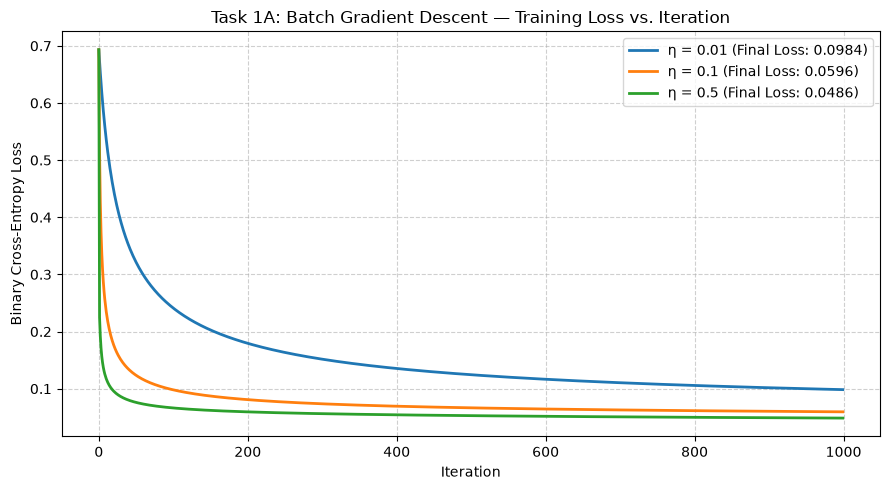

In [4]:
def train_gradient_descent(X, y, theta_init, lr=0.1, max_iter=1000, tol=1e-6):
    theta = theta_init.copy()
    n = X.shape[0]
    loss_history = []
    
    start_time = time.perf_counter()
    
    for i in range(max_iter):
        # Forward pass
        p = sigmoid(X @ theta)
        loss = compute_loss(y, p)
        loss_history.append(loss)
        
        # Compute gradient: g = (1/n) * X^T * (p - y)
        g = (1.0 / n) * (X.T @ (p - y))
        
        # Update parameters
        theta_new = theta - lr * g
        
        # Check convergence (L2 norm of parameter change)
        if np.linalg.norm(theta_new - theta) < tol:
            theta = theta_new
            loss_history.append(compute_loss(y, sigmoid(X @ theta)))
            break
            
        theta = theta_new
        
    total_time = time.perf_counter() - start_time
    num_iters = len(loss_history) - 1 if len(loss_history) > max_iter else i + 1
    avg_time_per_iter = total_time / num_iters
    
    return theta, loss_history, num_iters, total_time, avg_time_per_iter

# Compare learning rates: {0.01, 0.1, 0.5}
learning_rates = [0.01, 0.1, 0.5]
gd_results = {}

plt.figure(figsize=(9, 5))

for lr in learning_rates:
    theta_gd, losses, iters, t_tot, t_avg = train_gradient_descent(
        X_train_b, y_train, initial_theta, lr=lr, max_iter=1000, tol=1e-6
    )
    test_acc = accuracy_score(y_test, predict(X_test_b, theta_gd))
    gd_results[lr] = {
        "theta": theta_gd,
        "losses": losses,
        "iters": iters,
        "final_loss": losses[-1],
        "test_acc": test_acc,
        "total_time": t_tot,
        "avg_time": t_avg
    }
    plt.plot(losses, label=f"η = {lr} (Final Loss: {losses[-1]:.4f})", linewidth=2)

plt.title("Task 1A: Batch Gradient Descent — Training Loss vs. Iteration")
plt.xlabel("Iteration")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [11]:

import time
import numpy as np
from scipy.special import expit


def train_newtons_method(X, y, theta_init, max_iter=50, tol=1e-6):
    theta = theta_init.astype(float).copy()
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)

    n, d = X.shape
    loss_history = []
    damping = 1e-4

    # Stable logistic regression loss
    def calculate_loss(params):
        z = X @ params
        if not np.all(np.isfinite(z)):
            return np.inf
        return np.mean(np.logaddexp(0.0, z) - y * z)

    start_time = time.perf_counter()
    converged = False

    for i in range(max_iter):
        z = X @ theta
        p = expit(z)

        loss = calculate_loss(theta)
        loss_history.append(loss)

        # Gradient
        g = (X.T @ (p - y)) / n

        # Check convergence using the gradient
        if np.linalg.norm(g, ord=np.inf) < tol:
            converged = True
            break

        # Hessian without creating an n x n diagonal matrix
        s_diag = p * (1.0 - p)
        H = (X.T @ (X * s_diag[:, None])) / n

        # Symmetrize Hessian to reduce numerical asymmetry
        H = 0.5 * (H + H.T)

        # Damped Newton step
        try:
            delta = np.linalg.solve(
                H + damping * np.eye(d), g
            )
        except np.linalg.LinAlgError:
            delta = np.linalg.lstsq(
                H + max(damping, 1e-3) * np.eye(d),
                g,
                rcond=None
            )[0]

        if not np.all(np.isfinite(delta)):
            print(f"Non-finite Newton step at iteration {i + 1}.")
            break

        # Backtracking line search
        step_size = 1.0
        accepted = False

        for _ in range(30):
            theta_candidate = theta - step_size * delta
            candidate_loss = calculate_loss(theta_candidate)

            if (np.isfinite(candidate_loss)
                    and candidate_loss <= loss):
                accepted = True
                break

            step_size *= 0.5

        if not accepted:
            # Increase damping and retry on the next iteration
            damping = max(damping * 10.0, 1e-3)
            if damping > 1e8:
                break
            continue

        theta = theta_candidate
        loss_history.append(candidate_loss)

        # Reduce damping after a successful update
        damping = max(damping / 2.0, 1e-8)

        if np.linalg.norm(step_size * delta) < tol:
            converged = True
            break

    total_time = time.perf_counter() - start_time
    num_iters = i + 1
    avg_time_per_iter = total_time / num_iters

    # Record the final loss
    final_loss = calculate_loss(theta)
    if not loss_history or loss_history[-1] != final_loss:
        loss_history.append(final_loss)

    print("Convergence status:",
          "Converged" if converged else "Stopped before convergence")

    return (
        theta,
        loss_history,
        num_iters,
        total_time,
        avg_time_per_iter
    )


# Run Newton's Method with the same initialization
theta_nm, nm_losses, nm_iters, nm_tot_time, nm_avg_time = (
    train_newtons_method(
        X_train_b,
        y_train,
        initial_theta,
        max_iter=50,
        tol=1e-6
    )
)

nm_test_acc = accuracy_score(
    y_test,
    predict(X_test_b, theta_nm)
)

print(f"Newton's Method iterations: {nm_iters}")
print(f"Final Training Loss: {nm_losses[-1]:.6f}")
print(f"Test Accuracy: {nm_test_acc * 100:.2f}%")
print(f"Total Time: {nm_tot_time:.4f} seconds")
print(f"Average Time per Iteration: {nm_avg_time:.6f} seconds")


Convergence status: Converged
Newton's Method iterations: 16
Final Training Loss: 0.000011
Test Accuracy: 93.57%
Total Time: 0.0101 seconds
Average Time per Iteration: 0.000629 seconds


=== Task 1C: Performance Comparison ===


,Metric,Gradient Descent (η = 0.5),Newton's Method
0,Number of Iterations,1000,16
1,Final Training Loss,0.048604,0.000011
2,Test Accuracy (%),97.66%,93.57%
3,Total Training Time (s),0.043845,0.010060
4,Average Time per Iteration (s),4.384450e-05,6.287688e-04


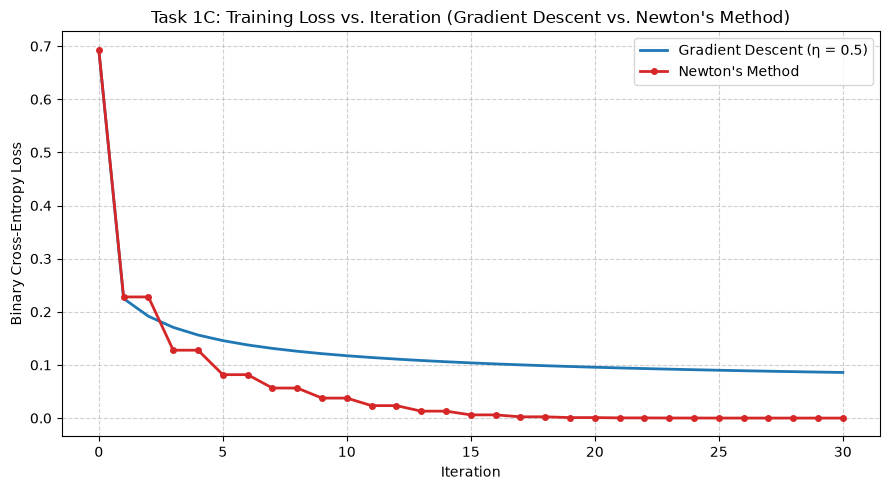

In [28]:
# Select best stable learning rate for Gradient Descent
best_lr = 0.5
best_gd = gd_results[best_lr]

# Create comparison table
comparison_df = pd.DataFrame({
    "Metric": [
        "Number of Iterations",
        "Final Training Loss",
        "Test Accuracy (%)",
        "Total Training Time (s)",
        "Average Time per Iteration (s)"
    ],
    f"Gradient Descent (η = {best_lr})": [
        best_gd["iters"],
        f"{best_gd['final_loss']:.6f}",
        f"{best_gd['test_acc'] * 100:.2f}%",
        f"{best_gd['total_time']:.6f}",
        f"{best_gd['avg_time']:.6e}"
    ],
    "Newton's Method": [
        nm_iters,
        f"{nm_losses[-1]:.6f}",
        f"{nm_test_acc * 100:.2f}%",
        f"{nm_tot_time:.6f}",
        f"{nm_avg_time:.6e}"
    ]
})

print("=== Task 1C: Performance Comparison ===")
display(comparison_df)

# Plot Loss vs Iteration for both methods on the same graph
plt.figure(figsize=(9, 5))
plt.plot(best_gd["losses"][:31], label=f"Gradient Descent (η = {best_lr})", color="tab:blue", linewidth=2)
plt.plot(nm_losses, label="Newton's Method", color="tab:red", marker="o", markersize=4, linewidth=2)

plt.title("Task 1C: Training Loss vs. Iteration (Gradient Descent vs. Newton's Method)")
plt.xlabel("Iteration")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()